# 2.1.3. Bài tập thực hành 1 - Titanic

**Mục tiêu:** xây dựng và so sánh cây quyết định, Random Forest theo các nhiệm vụ của bài mẫu 2.1.2.

Dự đoán nhãn Survived (0: không sống sót, 1: sống sót). Dùng train.csv có đặc trưng và nhãn; gender_submission.csv chỉ là mẫu kết quả, không dùng để huấn luyện hoặc chấm mô hình.

**Bài tham khảo trong đề:** [Kaggle](https://www.kaggle.com/code/dmilla/introduction-to-decision-trees-titanic-dataset). Mã dưới đây triển khai trên CSV thực tế trong thư mục data.

**Cách chạy:** chọn kernel **SGU HocMay (Anaconda ổn định)** rồi **Run All**. Cần numpy, pandas, matplotlib, scikit-learn. Có Graphviz thì vẽ bằng Graphviz; nếu chưa có sẽ dùng plot_tree.

## Nhiệm vụ 1: Xây dựng cây quyết định bằng Scikit-learn

### Bước 1. Nạp thư viện

Tổ chức import như bài mẫu; thêm Pipeline để xử lý dữ liệu đúng trên train của mỗi fold. Dùng n_jobs=1 để hạn chế tiến trình khi chạy notebook trên Windows; hình vẽ hiển thị ngay trong notebook.

In [1]:
from pathlib import Path
from time import perf_counter
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn import tree
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay)

get_ipython().run_line_magic('matplotlib', 'inline')
mpl.rcParams['figure.dpi'] = 120
RANDOM_STATE = 24

try:
    import graphviz
except ImportError:
    graphviz = None
if shutil.which('dot') is None:
    for bin_dir in [Path(r'C:\Program Files\Graphviz\bin'),
                    Path(r'C:\ProgramData\Anaconda3\Library\bin')]:
        if (bin_dir / 'dot.exe').is_file():
            os.environ['PATH'] = str(bin_dir) + os.pathsep + os.environ.get('PATH', '')
            break
print('Graphviz dot:', shutil.which('dot') or 'Chua co - se dung plot_tree')

Graphviz dot: C:\Program Files\Graphviz\bin\dot.EXE


### Bước 2. Nạp và khảo sát dữ liệu

Đọc đúng file trong data. Xem kích thước, các dòng đầu, kiểu dữ liệu, giá trị thiếu và bản ghi trùng trước khi chọn đặc trưng.

In [2]:
DATA_FILENAME = 'train.csv'
TARGET = 'Survived'
CLASS_NAMES = ['Khong song sot', 'Song sot']
RESULT_SLUG = 'Titanic'
numeric_features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Sex', 'Embarked']
feature_columns = numeric_features + categorical_features

# Tim data khi working directory o thu muc notebook hoac goc du an.
candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    candidates.extend([parent / 'data' / DATA_FILENAME,
                       parent / 'Lab05' / 'Giai_Thuat1' / 'data' / DATA_FILENAME])
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f'Chua tim thay data/{DATA_FILENAME} trong Giai_Thuat1.')
raw_df = pd.read_csv(DATA_PATH)
missing_columns = set(feature_columns + [TARGET]).difference(raw_df.columns)
if missing_columns:
    raise ValueError(f'Thieu cot: {sorted(missing_columns)}')
if raw_df[TARGET].isna().any() or set(raw_df[TARGET].unique()) != {0, 1}:
    raise ValueError('Nhan dich phai gom 0 va 1, khong bi thieu.')
print('File:', DATA_PATH)
print('Kich thuoc ban dau:', raw_df.shape)
display(raw_df.head())
display(pd.DataFrame({'dtype': raw_df.dtypes.astype(str), 'missing': raw_df.isna().sum()}))
print('So dong trung hoan toan:', int(raw_df.duplicated().sum()))

File: D:\SGU_HocMay_2026-2027\Lab05\Giai_Thuat1\data\train.csv
Kich thuoc ban dau: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,dtype,missing
PassengerId,int64,0
Survived,int64,0
Pclass,int64,0
Name,object,0
Sex,object,0
Age,float64,177
SibSp,int64,0
Parch,int64,0
Ticket,object,0
Fare,float64,0


So dong trung hoan toan: 0


### Bước 3. Chọn đặc trưng và làm sạch

Bỏ PassengerId (định danh), Name và Ticket để giữ mô hình cơ bản; bỏ Cabin do thiếu nhiều. Giữ 7 đặc trưng nêu trong mã. Điền thiếu biến số bằng trung vị và biến phân loại bằng giá trị phổ biến nhất; sau đó one-hot encoding. Cây không cần chuẩn hóa thang đo thông thường.

Chưa fit imputer hoặc encoder tại bước khảo sát này. Những bước cần học từ dữ liệu được đặt trong Pipeline ở bước sau.

Cot loai bo: ['PassengerId', 'Name', 'Ticket', 'Cabin']
Sau khi loai dong trung: (891, 12)


,count,percent
Survived,,
0,549,61.62
1,342,38.38


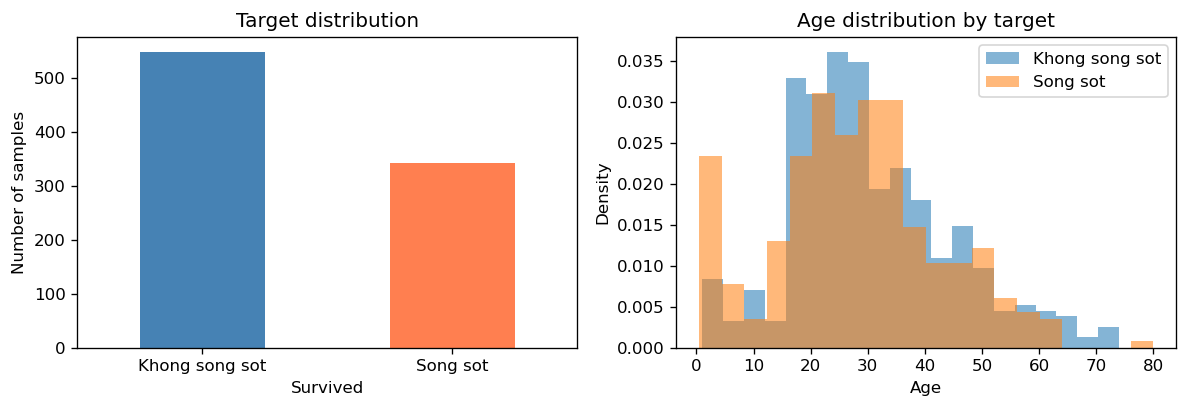

In [3]:
AGE_COLUMN = 'Age'

df = raw_df.drop_duplicates().reset_index(drop=True).copy()
items_to_remove = [c for c in df.columns if c not in feature_columns + [TARGET]]
features_response = feature_columns + [TARGET]
X = df[feature_columns].copy()
y = df[TARGET].astype(int)
print('Cot loai bo:', items_to_remove)
print('Sau khi loai dong trung:', df.shape)
class_summary = pd.DataFrame({
    'count': y.value_counts().sort_index(),
    'percent': y.value_counts(normalize=True).sort_index().mul(100)
})
display(class_summary.round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
class_summary['count'].plot.bar(ax=axes[0], color=['steelblue', 'coral'], rot=0)
axes[0].set_xticklabels(CLASS_NAMES)
axes[0].set_title('Target distribution')
axes[0].set_ylabel('Number of samples')
for label, group in df.groupby(TARGET):
    axes[1].hist(group[AGE_COLUMN], bins=20, alpha=0.55, density=True, label=CLASS_NAMES[int(label)])
axes[1].set(title='Age distribution by target', xlabel=AGE_COLUMN, ylabel='Density')
axes[1].legend()
plt.tight_layout()
plt.show()

### Bước 4. Chia train/test và định nghĩa tiền xử lý

Giữ 20% làm test và 80% làm train; stratify giữ tỷ lệ lớp tương đối. Test không tham gia tìm tham số. Pipeline fit lại imputer/encoder trên train của từng fold, tránh rò rỉ dữ liệu. OneHotEncoder bỏ qua nhóm chưa từng xuất hiện trong train. Bốn fold xáo trộn với seed cố định để tái lập.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
assert set(X_train.index).isdisjoint(X_test.index)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Ty le lop 1 train/test:', round(y_train.mean(), 4), round(y_test.mean(), 4))
numeric_transformer = Pipeline([('imputer', SimpleImputer(strategy='median'))])
categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])
cv_splitter = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

Train: (712, 7) | Test: (179, 7)
Ty le lop 1 train/test: 0.3834 0.3855


### Bước 5. Huấn luyện cây quyết định ban đầu

Tạo cây max_depth=2 để quan sát như bài mẫu. Dùng class_weight=balanced cho cây và rừng để lớp ít mẫu có trọng số lớn hơn. Đây là thiết lập minh họa cho nhãn mất cân bằng, không khẳng định luôn tối ưu; test vẫn giữ phân bố thật.

In [5]:
dt = Pipeline([
    ('preprocess', clone(preprocessor)),
    ('model', tree.DecisionTreeClassifier(
        criterion='gini', max_depth=2, class_weight='balanced', random_state=RANDOM_STATE
    ))
])
dt.fit(X_train, y_train)
print('Do sau cay minh hoa:', dt.named_steps['model'].get_depth())
print('So dac trung sau ma hoa:', len(dt.named_steps['preprocess'].get_feature_names_out()))

Do sau cay minh hoa: 2
So dac trung sau ma hoa: 10


### Bước 6. Vẽ cây quyết định

Lấy tên đặc trưng sau one-hot encoding để khớp số cột mô hình đã học. Đọc điều kiện từ nút gốc đến lá. Do dùng trọng số lớp, value trong hình là tỷ lệ có trọng số và có thể khác tỷ lệ đếm thô.

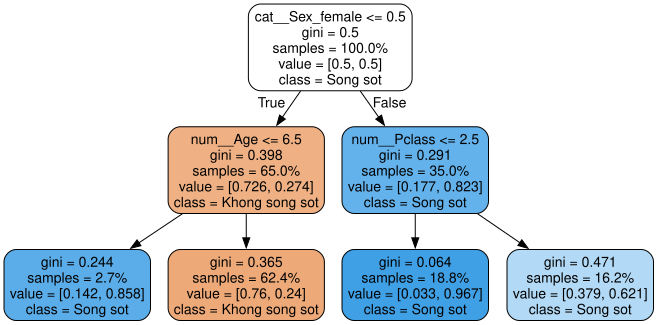

In [6]:
feature_names = dt.named_steps['preprocess'].get_feature_names_out().tolist()
if graphviz is not None and shutil.which('dot'):
    dot_data = tree.export_graphviz(
        dt.named_steps['model'], out_file=None,
        feature_names=feature_names, class_names=CLASS_NAMES,
        filled=True, rounded=True, proportion=True
    )
    graph = graphviz.Source(dot_data)
    display(graph)
else:
    plt.figure(figsize=(14, 6))
    tree.plot_tree(dt.named_steps['model'], feature_names=feature_names,
                   class_names=CLASS_NAMES, filled=True, rounded=True,
                   proportion=True, fontsize=8)
    plt.title('Decision Tree - max_depth=2')
    plt.tight_layout()
    plt.show()

## Nhiệm vụ 2: Tìm độ sâu tối ưu bằng GridSearchCV

### Bước 1. Khảo sát max_depth

Giữ lưới [1, 2, 4, 6, 8, 10, 12] và 4-fold CV như bài mẫu. scoring=roc_auc đánh giá bằng xác suất lớp 1. return_train_score=True lưu điểm train để so với validation. Tiền tố model__ chỉ tham số của bước model trong Pipeline. error_score=raise giúp hiện lỗi thực nếu có thay vì âm thầm bỏ qua cấu hình lỗi.

In [7]:
params = {'model__max_depth': [1, 2, 4, 6, 8, 10, 12]}
cv = GridSearchCV(
    dt, param_grid=params, scoring='roc_auc', cv=cv_splitter,
    n_jobs=1, refit=True, verbose=1, error_score='raise', return_train_score=True
)
t0 = perf_counter()
cv.fit(X_train, y_train)
dt_search_seconds = perf_counter() - t0
best_dt = cv.best_estimator_
print('Tham so tot nhat:', cv.best_params_)
print('Mean validation ROC AUC:', round(cv.best_score_, 4))
print('Thoi gian tim kiem (giay):', round(dt_search_seconds, 2))
cv_results_df = pd.DataFrame(cv.cv_results_)
display(cv_results_df[['param_model__max_depth', 'mean_train_score', 'mean_test_score',
                       'std_test_score', 'mean_fit_time']].round(4))

Fitting 4 folds for each of 7 candidates, totalling 28 fits


Tham so tot nhat: {'model__max_depth': 4}
Mean validation ROC AUC: 0.849
Thoi gian tim kiem (giay): 0.66


,param_model__max_depth,mean_train_score,mean_test_score,std_test_score,mean_fit_time
0,1,0.7659,0.7658,0.0287,0.0100
1,2,0.8292,0.8094,0.0203,0.0090
2,4,0.8961,0.8490,0.0211,0.0084
3,6,0.9325,0.8353,0.0247,0.0102
4,8,0.9588,0.8104,0.0356,0.0125
5,10,0.9808,0.8021,0.0423,0.0103
6,12,0.9932,0.7717,0.0445,0.0096


### Bước 2. Vẽ điểm train và validation theo độ sâu

mean_test_score trong cv_results_ là validation của CV, không phải tập test giữ riêng. Thanh sai số dùng std/sqrt(4) như bài mẫu để mô tả độ biến động; fold không độc lập hoàn toàn nên không coi thanh này là khoảng tin cậy thống kê chặt chẽ.

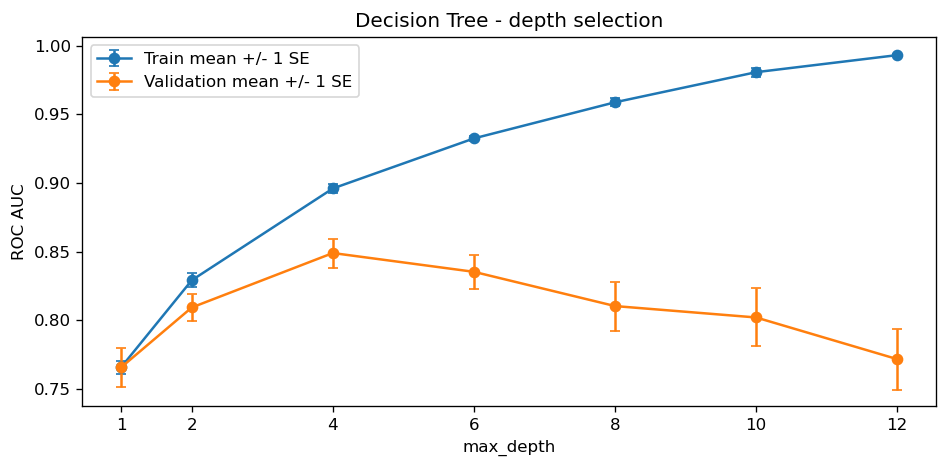

Chenh lech train - validation: 0.0470


In [8]:
depths = cv_results_df['param_model__max_depth'].astype(int)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(depths, cv_results_df['mean_train_score'],
            yerr=cv_results_df['std_train_score'] / np.sqrt(cv.n_splits_),
            marker='o', capsize=3, label='Train mean +/- 1 SE')
ax.errorbar(depths, cv_results_df['mean_test_score'],
            yerr=cv_results_df['std_test_score'] / np.sqrt(cv.n_splits_),
            marker='o', capsize=3, label='Validation mean +/- 1 SE')
ax.set(xlabel='max_depth', ylabel='ROC AUC', title='Decision Tree - depth selection')
ax.set_xticks(depths)
ax.legend()
plt.tight_layout()
plt.show()
best_row_dt = cv_results_df.loc[cv.best_index_]
dt_gap = float(best_row_dt['mean_train_score'] - best_row_dt['mean_test_score'])
print(f'Chenh lech train - validation: {dt_gap:.4f}')

## Nhiệm vụ 3: Xây dựng và tối ưu Random Forest

### Bước 1. Tạo rừng và tìm số cây tối ưu

Giữ max_depth=3, max_features=sqrt, bootstrap và lưới 10, 20, ..., 100 cây như bài mẫu. Dùng cùng các fold đã dùng cho cây quyết định. refit=True tự huấn luyện lại cấu hình tốt nhất trên toàn bộ train.

In [9]:
rf = Pipeline([
    ('preprocess', clone(preprocessor)),
    ('model', RandomForestClassifier(
        n_estimators=10, criterion='gini', max_depth=3,
        min_samples_split=2, min_samples_leaf=1,
        max_features='sqrt', bootstrap=True, class_weight='balanced',
        random_state=RANDOM_STATE, n_jobs=1
    ))
])
# Thu 10, 20, ..., 100 cay nhu bai mau.
rf_params_ex = {'model__n_estimators': list(range(10, 110, 10))}
cv_rf_ex = GridSearchCV(
    rf, param_grid=rf_params_ex, scoring='roc_auc', cv=cv_splitter,
    n_jobs=1, refit=True, verbose=1, error_score='raise', return_train_score=True
)
t0 = perf_counter()
cv_rf_ex.fit(X_train, y_train)
rf_search_seconds = perf_counter() - t0
best_rf = cv_rf_ex.best_estimator_
print('Tham so tot nhat:', cv_rf_ex.best_params_)
print('Mean validation ROC AUC:', round(cv_rf_ex.best_score_, 4))
print('Thoi gian tim kiem (giay):', round(rf_search_seconds, 2))
cv_rf_ex_results_df = pd.DataFrame(cv_rf_ex.cv_results_)
display(cv_rf_ex_results_df[['param_model__n_estimators', 'mean_train_score',
                             'mean_test_score', 'std_test_score', 'mean_fit_time']].round(4))

Fitting 4 folds for each of 10 candidates, totalling 40 fits


Tham so tot nhat: {'model__n_estimators': 50}
Mean validation ROC AUC: 0.8589
Thoi gian tim kiem (giay): 3.61


,param_model__n_estimators,mean_train_score,mean_test_score,std_test_score,mean_fit_time
0,10,0.8775,0.8481,0.0287,0.0194
1,20,0.8792,0.8554,0.0254,0.0362
2,30,0.8797,0.8565,0.0219,0.0408
3,40,0.8802,0.8589,0.0200,0.0518
4,50,0.8808,0.8589,0.0196,0.0629
5,60,0.8805,0.8583,0.0214,0.0740
6,70,0.8807,0.8576,0.0210,0.0935
7,80,0.8815,0.8575,0.0219,0.0964
8,90,0.8813,0.8561,0.0240,0.1136
9,100,0.8812,0.8552,0.0251,0.1213


### Bước 2. Vẽ thời gian huấn luyện và ROC AUC theo số cây

Biểu đồ trái thể hiện chi phí tính toán; biểu đồ phải là điểm validation. Thời gian phụ thuộc máy và tải hệ thống tại lúc chạy.

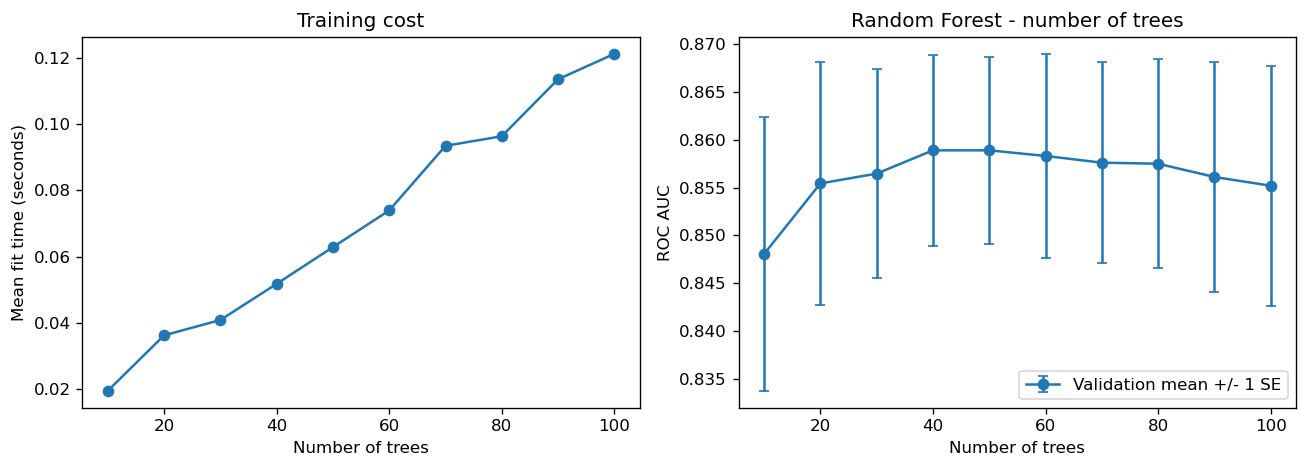

In [10]:
numbers_of_trees = cv_rf_ex_results_df['param_model__n_estimators'].astype(int)
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(numbers_of_trees, cv_rf_ex_results_df['mean_fit_time'], '-o')
axs[0].set(xlabel='Number of trees', ylabel='Mean fit time (seconds)', title='Training cost')
axs[1].errorbar(numbers_of_trees, cv_rf_ex_results_df['mean_test_score'],
                yerr=cv_rf_ex_results_df['std_test_score'] / np.sqrt(cv_rf_ex.n_splits_),
                marker='o', capsize=3, label='Validation mean +/- 1 SE')
axs[1].set(xlabel='Number of trees', ylabel='ROC AUC', title='Random Forest - number of trees')
axs[1].legend()
plt.tight_layout()
plt.show()

### Bước 3. Xem tầm quan trọng của đặc trưng

Đọc feature_importances_ từ rừng tốt nhất với đúng tên cột sau mã hóa. MDI tổng hợp mức giảm impurity trên train; có thể thiên về biến nhiều giá trị và bị ảnh hưởng bởi tương quan giữa các biến. Không diễn giải như bằng chứng nhân quả.

,Feature,Importance
0,cat__Sex_male,0.2894
1,cat__Sex_female,0.2509
2,num__Fare,0.1916
3,num__Pclass,0.1022
4,num__Age,0.0550
5,num__SibSp,0.0475
6,num__Parch,0.0270
7,cat__Embarked_C,0.0238
8,cat__Embarked_S,0.0072
9,cat__Embarked_Q,0.0054


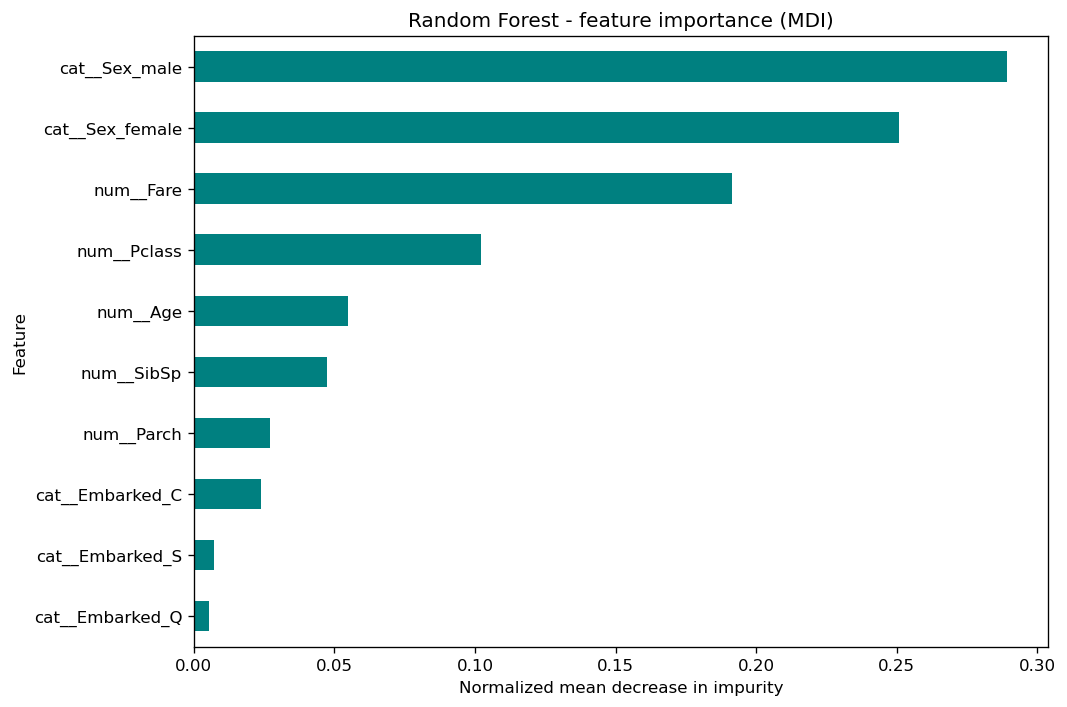

Dac trung noi bat nhat theo MDI: cat__Sex_male


In [11]:
rf_feature_names = best_rf.named_steps['preprocess'].get_feature_names_out()
feat_imp_df = pd.DataFrame({
    'Feature': rf_feature_names,
    'Importance': best_rf.named_steps['model'].feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)
display(feat_imp_df.round(4))
feat_imp_df.sort_values('Importance').plot.barh(
    x='Feature', y='Importance', figsize=(9, 6), legend=False, color='teal'
)
plt.title('Random Forest - feature importance (MDI)')
plt.xlabel('Normalized mean decrease in impurity')
plt.tight_layout()
plt.show()
print('Dac trung noi bat nhat theo MDI:', feat_imp_df.iloc[0]['Feature'])

## Đánh giá cuối cùng trên tập test

Chọn mô hình theo CV trước khi xem test. Báo cáo cả hai mô hình đã chốt trên cùng test: accuracy, precision, recall, F1, ROC AUC, average precision, confusion matrix và ROC. Nhãn 1 là lớp dương. ROC AUC dùng predict_proba thay vì nhãn cứng 0/1.


Decision Tree
                precision    recall  f1-score   support

Khong song sot       0.86      0.70      0.77       110
      Song sot       0.63      0.81      0.71        69

      accuracy                           0.74       179
     macro avg       0.74      0.76      0.74       179
  weighted avg       0.77      0.74      0.75       179


Random Forest
                precision    recall  f1-score   support

Khong song sot       0.83      0.82      0.82       110
      Song sot       0.71      0.72      0.72        69

      accuracy                           0.78       179
     macro avg       0.77      0.77      0.77       179
  weighted avg       0.78      0.78      0.78       179



,CV ROC AUC,Test accuracy,Test precision,Test recall,Test F1,Test ROC AUC,Test average precision
Model,,,,,,,
Decision Tree,0.8490,0.7430,0.6292,0.8116,0.7089,0.8260,0.7287
Random Forest,0.8589,0.7821,0.7143,0.7246,0.7194,0.8438,0.8205


Mo hinh duoc chon theo CV: Random Forest
Accuracy neu luon du doan lop pho bien: 0.6145


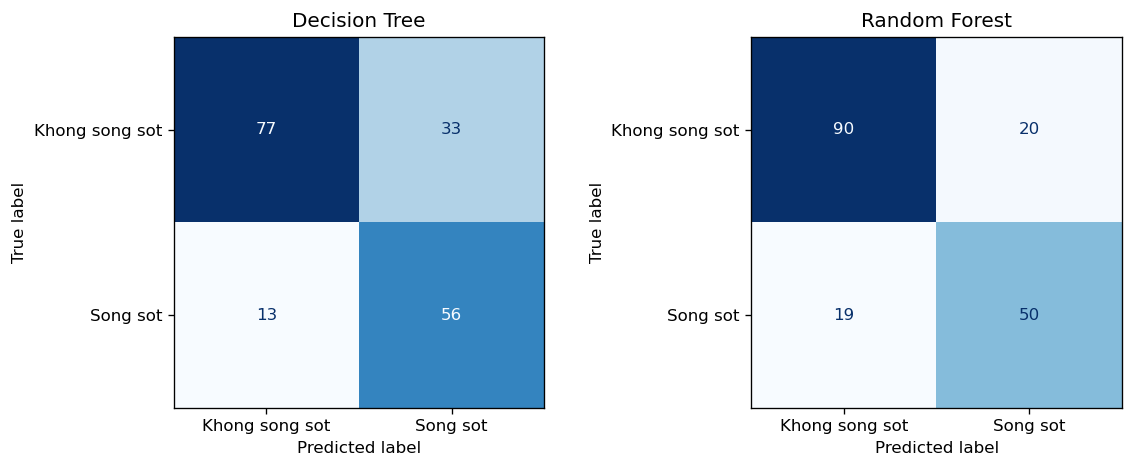

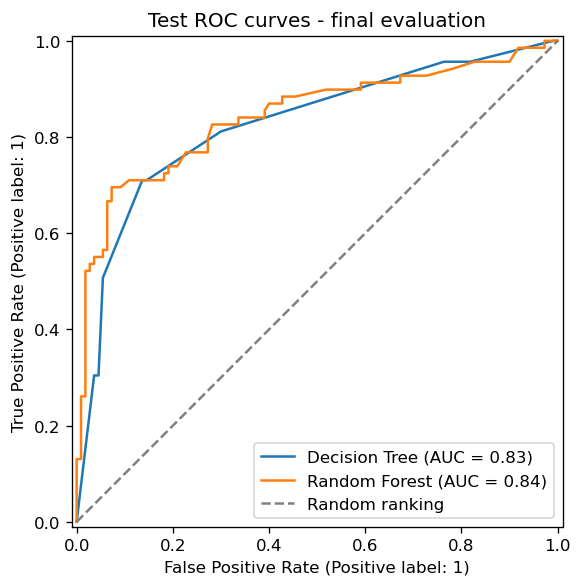

In [12]:
# Chot mo hinh bang diem CV truoc khi xem test.
selected_by_cv = 'Decision Tree' if cv.best_score_ >= cv_rf_ex.best_score_ else 'Random Forest'
models = {'Decision Tree': best_dt, 'Random Forest': best_rf}
cv_scores = {'Decision Tree': cv.best_score_, 'Random Forest': cv_rf_ex.best_score_}
records, predictions, probabilities = [], {}, {}
for name, model in models.items():
    positive_index = list(model.classes_).index(1)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, positive_index]
    predictions[name] = y_pred
    probabilities[name] = y_proba
    records.append({
        'Model': name, 'CV ROC AUC': cv_scores[name],
        'Test accuracy': accuracy_score(y_test, y_pred),
        'Test precision': precision_score(y_test, y_pred, zero_division=0),
        'Test recall': recall_score(y_test, y_pred, zero_division=0),
        'Test F1': f1_score(y_test, y_pred, zero_division=0),
        'Test ROC AUC': roc_auc_score(y_test, y_proba),
        'Test average precision': average_precision_score(y_test, y_proba)
    })
    print('\n' + name)
    print(classification_report(y_test, y_pred, labels=[0, 1],
                                target_names=CLASS_NAMES, zero_division=0))
comparison_df = pd.DataFrame(records).set_index('Model')
display(comparison_df.round(4))
print('Mo hinh duoc chon theo CV:', selected_by_cv)
print('Accuracy neu luon du doan lop pho bien:', round(y_test.value_counts(normalize=True).max(), 4))

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axs, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], labels=[0, 1], display_labels=CLASS_NAMES,
        cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(6, 5))
for name in models:
    RocCurveDisplay.from_predictions(y_test, probabilities[name], name=name, ax=ax)
ax.plot([0, 1], [0, 1], '--', color='gray', label='Random ranking')
ax.set_title('Test ROC curves - final evaluation')
ax.legend()
plt.tight_layout()
plt.show()

## Tổng hợp nhận xét và lưu kết quả

Nhận xét được tạo từ kết quả chạy thực tế; lưu bảng và dự đoán vào ket_qua để kiểm tra lại.

In [13]:
best_dt_depth = int(cv.best_params_['model__max_depth'])
best_rf_count = int(cv_rf_ex.best_params_['model__n_estimators'])
best_row_rf = cv_rf_ex_results_df.loc[cv_rf_ex.best_index_]
rf_gap = float(best_row_rf['mean_train_score'] - best_row_rf['mean_test_score'])
selected_result = comparison_df.loc[selected_by_cv]
final_auc = selected_result['Test ROC AUC']
final_f1 = selected_result['Test F1']
final_recall = selected_result['Test recall']
top_features = ', '.join(feat_imp_df.head(3)['Feature'].tolist())
notes = '\n\n'.join([
    '### Nhận xét kết quả',
    f'- Sau làm sạch có **{len(df):,} dòng**; train **{len(X_train):,}**, test **{len(X_test):,}**. Tỷ lệ lớp 1 là **{y.mean():.2%}**.',
    f'- Cây quyết định chọn **max_depth = {best_dt_depth}**, CV ROC AUC **{cv.best_score_:.4f}**. Khoảng cách train - validation là **{dt_gap:.4f}**.',
    f'- Random Forest chọn **{best_rf_count} cây**, giữ **max_depth = 3** như bài mẫu; CV ROC AUC **{cv_rf_ex.best_score_:.4f}**. Khoảng cách train - validation là **{rf_gap:.4f}**.',
    f'- Chọn **{selected_by_cv}** theo CV trước khi xem test. Mô hình được chọn có test **ROC AUC {final_auc:.4f}**, **F1 {final_f1:.4f}**, **recall lớp 1 {final_recall:.4f}**.',
    f'- Ba đặc trưng đứng đầu theo MDI của rừng: **{top_features}**. Đây là mức quan trọng phụ thuộc mô hình, không chứng minh quan hệ nhân quả.',
    '- Điểm train cao hơn validation nhiều gợi ý quá khớp; hai điểm thấp có thể gợi ý thiếu khớp. Khoảng cách điểm là dấu hiệu tham khảo, không đo trực tiếp bias và variance.',
    '- Tăng số cây làm tăng chi phí nhưng không bảo đảm AUC tăng liên tục. Cấu hình tốt nhất chỉ trong lưới đã thử, với rừng giới hạn độ sâu 3 để bám bài mẫu.',
    '- Test chỉ được dùng ở phần đánh giá cuối, không dùng chọn lại tham số. Recall, precision, F1 và average precision bổ sung cho accuracy khi nhãn mất cân bằng. Báo cáo dùng ngưỡng phân loại mặc định.'
])
display(Markdown(notes))

# Luu cac bang so lieu va du doan de kiem tra lai.
RESULTS_DIR = DATA_PATH.parent.parent / 'ket_qua' / RESULT_SLUG
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(RESULTS_DIR / 'so_sanh_mo_hinh.csv', encoding='utf-8-sig')
feat_imp_df.to_csv(RESULTS_DIR / 'feature_importance.csv', index=False, encoding='utf-8-sig')
cv_results_df.to_csv(RESULTS_DIR / 'decision_tree_cv.csv', index=False, encoding='utf-8-sig')
cv_rf_ex_results_df.to_csv(RESULTS_DIR / 'random_forest_cv.csv', index=False, encoding='utf-8-sig')
pd.DataFrame({
    'row_index': X_test.index, 'actual': y_test.to_numpy(),
    'decision_tree_prediction': predictions['Decision Tree'],
    'decision_tree_probability': probabilities['Decision Tree'],
    'random_forest_prediction': predictions['Random Forest'],
    'random_forest_probability': probabilities['Random Forest']
}).to_csv(RESULTS_DIR / 'du_doan_test.csv', index=False, encoding='utf-8-sig')
(RESULTS_DIR / 'nhan_xet.md').write_text(notes, encoding='utf-8')
print('Bao cao da luu:', RESULTS_DIR)

### Nhận xét kết quả

- Sau làm sạch có **891 dòng**; train **712**, test **179**. Tỷ lệ lớp 1 là **38.38%**.

- Cây quyết định chọn **max_depth = 4**, CV ROC AUC **0.8490**. Khoảng cách train - validation là **0.0470**.

- Random Forest chọn **50 cây**, giữ **max_depth = 3** như bài mẫu; CV ROC AUC **0.8589**. Khoảng cách train - validation là **0.0218**.

- Chọn **Random Forest** theo CV trước khi xem test. Mô hình được chọn có test **ROC AUC 0.8438**, **F1 0.7194**, **recall lớp 1 0.7246**.

- Ba đặc trưng đứng đầu theo MDI của rừng: **cat__Sex_male, cat__Sex_female, num__Fare**. Đây là mức quan trọng phụ thuộc mô hình, không chứng minh quan hệ nhân quả.

- Điểm train cao hơn validation nhiều gợi ý quá khớp; hai điểm thấp có thể gợi ý thiếu khớp. Khoảng cách điểm là dấu hiệu tham khảo, không đo trực tiếp bias và variance.

- Tăng số cây làm tăng chi phí nhưng không bảo đảm AUC tăng liên tục. Cấu hình tốt nhất chỉ trong lưới đã thử, với rừng giới hạn độ sâu 3 để bám bài mẫu.

- Test chỉ được dùng ở phần đánh giá cuối, không dùng chọn lại tham số. Recall, precision, F1 và average precision bổ sung cho accuracy khi nhãn mất cân bằng. Báo cáo dùng ngưỡng phân loại mặc định.

Bao cao da luu: D:\SGU_HocMay_2026-2027\Lab05\Giai_Thuat1\ket_qua\Titanic


### Diễn giải bổ sung

Hai mô hình được so sánh trên cùng 179 hành khách của test. Ở lần chạy lưu trong notebook, Random Forest có ROC AUC và accuracy cao hơn cây quyết định, nhưng cây quyết định có recall lớp sống sót cao hơn. Vì vậy, chọn tiêu chí đánh giá phải gắn với mục tiêu, không chỉ nhìn một chỉ số. Mô hình được chốt bằng điểm CV, không chọn lại theo test.

## Tài liệu kỹ thuật

- [Scikit-learn - ColumnTransformer](https://scikit-learn.org/1.7/auto_examples/compose/plot_column_transformer_mixed_types.html)
- [GridSearchCV](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.GridSearchCV.html)
- [RandomForestClassifier](https://scikit-learn.org/1.7/modules/generated/sklearn.ensemble.RandomForestClassifier.html)